# 02 · GLM baselines (the actuarial standard)

Pricing teams have used **Generalised Linear Models** for decades because they are transparent, auditable and
produce multiplicative *relativities* ("a 20-year-old costs 2.4× a 45-year-old, all else equal").
Any machine-learning challenger has to beat this baseline *and* be explainable to a pricing committee.

| Model | Family / link | Target | Weights |
|---|---|---|---|
| Frequency | Poisson / log | claim count | offset = log(exposure) |
| Severity | Gamma / log | average cost per claim (claims only) | number of claims |

`pure premium = frequency × severity`

In [1]:
%load_ext autoreload
%autoreload 2
import time
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

from motor_pricing.config import PROCESSED_DIR
from motor_pricing.data import load_data, split_data
from motor_pricing.evaluation import (
    gini, lorenz_curve, null_rates, scorecard, segment_calibration,
)
from motor_pricing.features import (
    DRIVAGE_LABELS, FREQ_FORMULA, SEV_FORMULA, add_features, add_glm_bands,
)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:,.4f}".format)

In [2]:
df = load_data()
train, valid, test = split_data(df)
# GLMs need binned / clipped features. Same clipping as the GBMs so the comparison is fair.
tr, va, te = (add_glm_bands(add_features(d)) for d in (train, valid, test))
print(FREQ_FORMULA, "\n\n", SEV_FORMULA)

ClaimNb ~ C(DrivAgeBand, Treatment('41-50')) + C(VehAgeBand, Treatment('6-10')) + C(VehPower) + BonusMalus + LogDensity + C(Area) + C(VehGas) + C(VehBrand) + C(Region) 

 AvgClaim ~ C(DrivAgeBand, Treatment('41-50')) + C(VehAgeBand, Treatment('6-10')) + BonusMalus + LogDensity + C(Area) + C(VehGas)


## 1. Frequency model — Poisson GLM with exposure offset
`log E[claims] = log(exposure) + β·x`, so `exp(β)` is the relativity of each level versus the reference level
(reference = most populated band, e.g. drivers aged 41-50).

In [3]:
t0 = time.time()
freq_glm = smf.glm(
    FREQ_FORMULA, data=tr, family=sm.families.Poisson(), offset=np.log(tr["Exposure"])
).fit()
print(f"fitted in {time.time() - t0:.1f}s | converged: {freq_glm.converged} | n params: {len(freq_glm.params)}")

fitted in 10.8s | converged: True | n params: 60


In [4]:
rel = pd.DataFrame({
    "relativity": np.exp(freq_glm.params),
    "lower_95": np.exp(freq_glm.conf_int()[0]),
    "upper_95": np.exp(freq_glm.conf_int()[1]),
    "p_value": freq_glm.pvalues,
})
rel.index = rel.index.str.replace(r"C\((\w+)(, Treatment\('[^']*'\))?\)\[T\.(.*)\]", r"\1 = \3", regex=True)
rel.loc[[i for i in rel.index if i.startswith(("DrivAgeBand", "VehAgeBand"))]]

,relativity,lower_95,upper_95,p_value
DrivAgeBand = 18-20,1.1339,1.0219,1.2581,0.0179
DrivAgeBand = 21-25,0.7102,0.6627,0.7611,0.0000
DrivAgeBand = 26-30,0.6303,0.5944,0.6684,0.0000
DrivAgeBand = 31-40,0.7495,0.7182,0.7821,0.0000
DrivAgeBand = 51-60,0.9477,0.9073,0.9898,0.0154
DrivAgeBand = 61-70,0.8821,0.8335,0.9336,0.0000
DrivAgeBand = 71+,0.9444,0.8843,1.0085,0.0877
VehAgeBand = 0,0.9954,0.9224,1.0741,0.9055
VehAgeBand = 1-2,1.0264,0.9794,1.0757,0.2765
VehAgeBand = 11-15,0.8704,0.8353,0.9069,0.0000


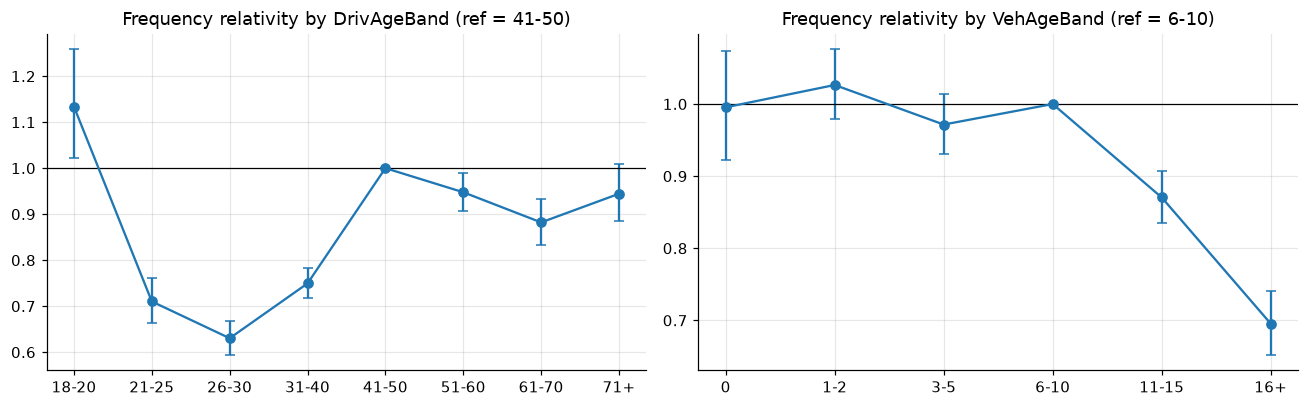

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, prefix, order in zip(
    axes, ["DrivAgeBand", "VehAgeBand"],
    [DRIVAGE_LABELS, ["0", "1-2", "3-5", "6-10", "11-15", "16+"]], strict=True,
):
    sub = rel.loc[[i for i in rel.index if i.startswith(prefix)]].copy()
    sub.index = [i.split(" = ")[1] for i in sub.index]
    ref = "41-50" if prefix == "DrivAgeBand" else "6-10"
    sub.loc[ref] = [1.0, 1.0, 1.0, np.nan]
    sub = sub.reindex(order)
    ax.errorbar(range(len(sub)), sub["relativity"],
                yerr=[sub["relativity"] - sub["lower_95"], sub["upper_95"] - sub["relativity"]],
                fmt="o-", capsize=3)
    ax.axhline(1, color="k", lw=0.8)
    ax.set_xticks(range(len(sub)))
    ax.set_xticklabels(sub.index)
    ax.set_title(f"Frequency relativity by {prefix} (ref = {ref})")
plt.tight_layout()

## 2. Severity model — Gamma GLM on claims only
Fitted on policies with ≥1 claim; the response is the **average cost per claim** and each row is weighted by its number of claims.
We use fewer rating factors than for frequency because severity carries far less signal and is easy to over-fit.

In [6]:
cl = tr[tr["ClaimNb"] > 0].copy()
cl["AvgClaim"] = cl["ClaimAmount"] / cl["ClaimNb"]
sev_glm = smf.glm(
    SEV_FORMULA, data=cl, family=sm.families.Gamma(link=sm.families.links.Log()),
    freq_weights=cl["ClaimNb"],
).fit()
print(f"claims-only training rows: {len(cl):,} | converged: {sev_glm.converged} | dispersion: {sev_glm.scale:.2f}")
sev_rel = np.exp(sev_glm.params).rename("relativity").to_frame()
sev_rel.index = sev_rel.index.str.replace(r"C\((\w+)(, Treatment\('[^']*'\))?\)\[T\.(.*)\]", r"\1 = \3", regex=True)
sev_rel

claims-only training rows: 17,460 | converged: True | dispersion: 12.89


,relativity
Intercept,"1,397.9104"
DrivAgeBand = 18-20,1.8727
DrivAgeBand = 21-25,1.3677
DrivAgeBand = 26-30,1.1154
DrivAgeBand = 31-40,1.1350
DrivAgeBand = 51-60,1.0570
DrivAgeBand = 61-70,1.0900
DrivAgeBand = 71+,1.7296
VehAgeBand = 0,1.0511
VehAgeBand = 1-2,1.0863


## 3. Sanity check: the *balance property*
A Poisson GLM with a log link and an intercept reproduces total claims on the training data. If this fails, something is wrong with the offset.

In [7]:
pred_claims = (freq_glm.predict(tr) * tr["Exposure"]).sum()
print(f"predicted claims (train): {pred_claims:,.1f} | actual: {tr['ClaimNb'].sum():,}")

predicted claims (train): 18,459.0 | actual: 18,459


## 4. Score the test set
`freq_glm.predict(df)` returns the **annual** claim frequency (exp(xβ) with no offset), and
`pure_premium = frequency × severity` is the expected loss per policy-year.

In [8]:
glm_pred = pd.DataFrame({
    "frequency": freq_glm.predict(te).to_numpy(),
    "severity": sev_glm.predict(te).to_numpy(),
})
glm_pred["pure_premium"] = glm_pred["frequency"] * glm_pred["severity"]

null = null_rates(train)
card = scorecard(test, {"Poisson×Gamma GLM": glm_pred}, null)
card

,freq_poisson_dev,sev_gamma_dev,pp_tweedie_dev,gini,gini_vs_best_possible
null (portfolio average),0.4763,1.4122,78.9311,0.0118,0.0120
Poisson×Gamma GLM,0.4559,1.4182,75.1845,0.3129,0.3183


**How to read the scorecard**
* *Deviance* – lower is better (it is the likelihood-based loss each model is fitted on).
* *Gini* – how well the model **ranks** risks (0 = random, higher = better). `gini_vs_best_possible` rescales by the best Gini achievable on this noisy data.
* The null row is "charge everyone the portfolio average" — any real model must beat it.

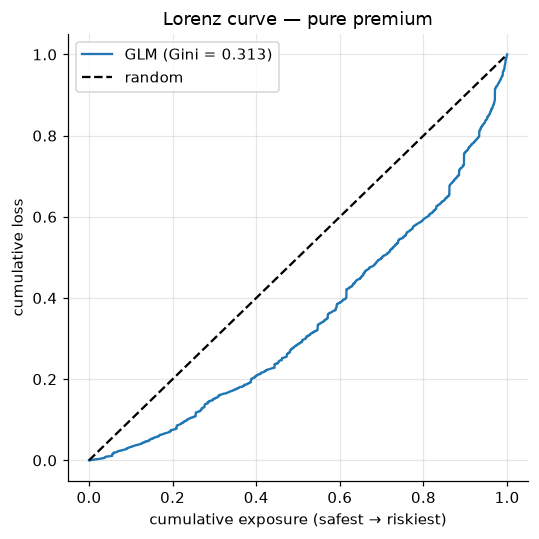

In [9]:
x, y = lorenz_curve(test["ClaimAmount"], glm_pred["pure_premium"], test["Exposure"])
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(x, y, label=f"GLM (Gini = {gini(test['ClaimAmount'], glm_pred['pure_premium'], test['Exposure']):.3f})")
ax.plot([0, 1], [0, 1], "k--", label="random")
ax.set(xlabel="cumulative exposure (safest → riskiest)", ylabel="cumulative loss", title="Lorenz curve — pure premium")
ax.legend()
plt.tight_layout()

## 5. Calibration by segment
Does predicted ≈ actual within each driver-age band? Model *bias* in a segment is a pricing leak.

,exposure_share,actual,GLM
segment,,,
18-20,0.0073,588.7025,884.6633
21-25,0.0385,186.2331,324.3701
26-30,0.0819,174.1800,164.6083
31-40,0.2323,144.0959,136.9093
41-50,0.2453,146.1169,130.2291
51-60,0.2133,122.6432,124.8278
61-70,0.1067,98.0518,113.7691
71+,0.0746,126.3674,181.3591


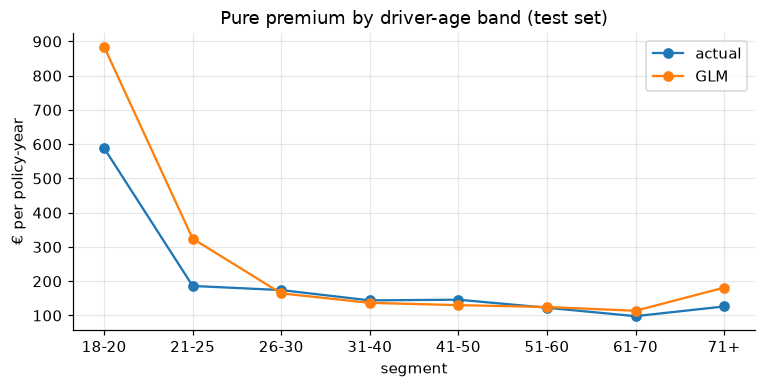

In [10]:
cal = segment_calibration(
    te["DrivAgeBand"], test["ClaimAmount"], test["Exposure"], {"GLM": glm_pred["pure_premium"]}
).reindex(DRIVAGE_LABELS)
ax = cal[["actual", "GLM"]].plot(marker="o", figsize=(8, 3.5), title="Pure premium by driver-age band (test set)")
ax.set_ylabel("€ per policy-year")
cal

## 6. Save GLM predictions for the model comparison in notebooks 03 and 04

In [11]:
out = glm_pred.assign(IDpol=test["IDpol"].to_numpy())
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
out.to_parquet(PROCESSED_DIR / "glm_test_predictions.parquet", index=False)
print("saved", PROCESSED_DIR / "glm_test_predictions.parquet")

saved data/processed/glm_test_predictions.parquet


## Takeaways
* The GLM gives a transparent, auditable benchmark with clear relativities.
* Limitations to explore next: it only captures **additive log-effects** (no interactions unless hand-coded) and relies on manual binning.
* Next: **`03_lightgbm_challengers.ipynb`** — can a gradient-boosted model find structure the GLM misses, while still respecting business rules (monotonic bonus-malus)?